In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')


project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *
# import plot_preferences

2024-07-16 16:19:56.502219: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-07-16 16:19:56.550862: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-07-16 16:19:56.550895: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-07-16 16:19:56.552207: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-07-16 16:19:56.559234: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-07-16 16:19:56.560233: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [ ]:
load_path = project_folder + 'analyses/noise correlations/saved/opticflow/0 - 22.dat'
load_path_sh = project_folder + 'analyses/noise correlations/saved/opticflow/(shuffled trial per time) 0 - 22.dat'

with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

with open(load_path_sh, 'rb') as f:
    data_dict_sh = pickle.load(f)
data_sh = Namespace(**data_dict_sh)

In [4]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, stdevs

In [5]:
mi_averages, mi_stdevs = process_trials(data.mi_averages_test, data.mi_stdevs_test)
mi_averages_sh, mi_stdevs_sh = process_trials(data_sh.mi_averages_test, data_sh.mi_stdevs_test)

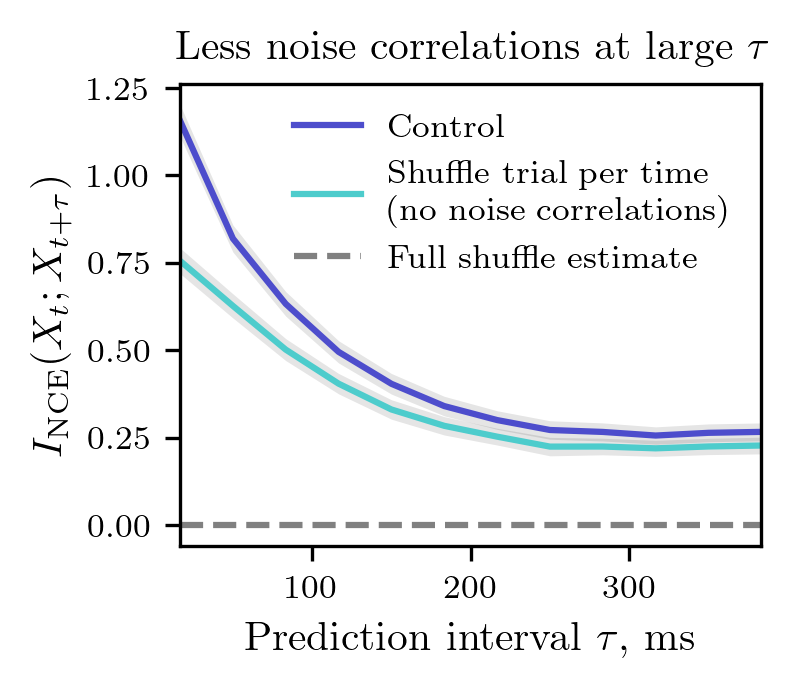

In [6]:
alp = 0.1

binsize = 1000 / 60
x = (data.V_E_buffer_array + 1) * binsize
dt = 1000 / 60

fig, ax = plt.subplots(figsize=[5*plot_scale,4*plot_scale], dpi=300)

y = mi_averages / np.log(2)
yerr = mi_stdevs / np.log(2)
ax.plot(x, y, color=(0.3,0.3,0.8), label="Control")
ax.fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0, zorder=1)

y = mi_averages_sh / np.log(2)
yerr = mi_stdevs_sh / np.log(2)
ax.plot(x, y, color=(0.3,0.8,0.8), label="Shuffle trial per time \n (no noise correlations)")
ax.fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0, zorder=1)

ax.set_xlabel(r'Prediction interval $\tau$, ms')
ax.set_ylabel(r'$I_{\mathrm{NCE}}(X_t; X_{t+\tau})$')
ax.axhline(0.001 / np.log(2), linestyle='--', color='grey', label='Full shuffle estimate')
ax.set_xlim(x[0], x[-1])
ax.legend(frameon=False)
ax.set_title('Less noise correlations at large $\\tau$')

plt.savefig('./plots/trial shuffle effect vs interval.png', dpi=3000)

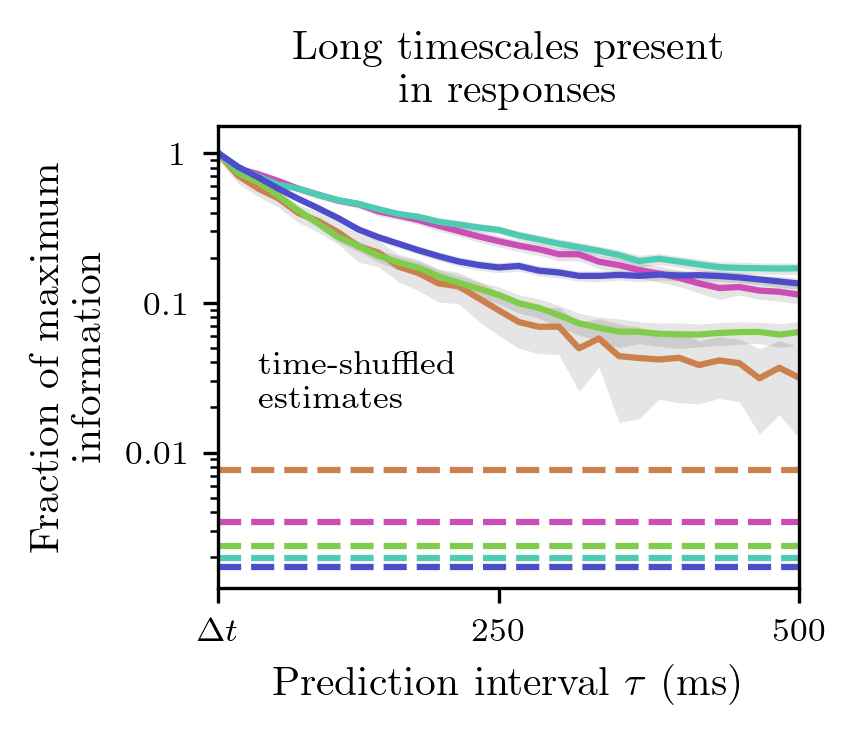

In [ ]:
alp = 0.1

binsize = 1000 / 60
x = (data[0].V_E_buffer_array + 1) * binsize
dt = 1000 / 60

fig, ax = plt.subplots(figsize=[5*plot_scale,4*plot_scale], dpi=300)

for j, stim in enumerate(stimuli):
    curmax = np.max(average_test[j])
    y = average_test[j] / curmax
    yerr = stdevs_test[j] / curmax
    # ax.semilogy(x, y, color=colors[j], label=stim)
    ax.semilogy(x, y, color=colors[j])
    # ax.plot(x, y, color=colors[j], label=stim)
    ax.fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)
    # ax.axhline(stdevs_shuffle[j] / curmax, color=colors[j], linestyle='--')
    # ax.axhline(stdevs_shuffle[j] / curmax, color=colors[j], linestyle='--')
    ax.axhline(np.sqrt(average_shuffle[j]**2 + stdevs_shuffle[j]**2) / curmax, color=colors[j], linestyle='--')

ax.plot([],[], color=(0.7,0.7,0.7), linestyle='--', label='time shuffle')
# ax.axhline(0, color=(0,0,0), linestyle='--')
ax.set_xlabel(r'Prediction interval $\tau$ (ms)')
# ax.set_ylabel('$\log(I_{\mathrm{NCE}}(X;Y)(\\tau) / I_{\mathrm{NCE}}(X;Y)(\Delta t))$')
# ax.set_ylabel('$\log(I(X;Y)(\\tau) / I(X;Y)(\Delta t))$')
ax.set_ylabel('Fraction of maximum\n information')
ax.set_xlim(x[0],x[-1])
# ax.set_ylim(0)
ax.set_xticks([dt, 250, 500]);
ax.set_yticks([1,0.1,0.01])
ax.set_yticklabels([1,0.1,0.01])
ax.set_xticklabels([r"$\Delta t$",250,500]);
# ax.set_title("Fraction of maximum predictive \n information vs. interval")
ax.set_title("Long timescales present\n  in responses")
# ax.legend(fontsize=legend_size, edgecolor=(1,1,1,0), loc='center left')
ax.text(50, 0.02, 'time-shuffled\n estimates')

# ax.legend(frameon=False)
# ax[0].legend(handles=lines_right)
    
# plt.savefig('./plots/log I vs tau.png', dpi=3000)